In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
import warnings
warnings.filterwarnings('ignore')

In [2]:
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
NUM_CLASSES = 3
EPOCHS = 50

print("="*70)
print("ACTION RECOGNITION CNN - CAPSTONE PROJECT")
print("="*70)

ACTION RECOGNITION CNN - CAPSTONE PROJECT


In [ ]:
print("\n[STEP 1] DATA PREPROCESSING - NORMALIZATION & AUGMENTATION")
print("-"*70)

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    zoom_range=0.2,
    shear_range=0.15,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)


[STEP 1] DATA PREPROCESSING - NORMALIZATION & AUGMENTATION
----------------------------------------------------------------------


In [4]:
print("\n[STEP 2] LOAD IMAGES FROM FOLDERS")
print("-"*70)

train_generator = train_datagen.flow_from_directory(
    'dataset/train',
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

test_generator = test_datagen.flow_from_directory(
    'dataset/test',
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print(f" Training images loaded: {train_generator.samples}")
print(f" Test images loaded: {test_generator.samples}")
print(f" Classes: {list(train_generator.class_indices.keys())}")


[STEP 2] LOAD IMAGES FROM FOLDERS
----------------------------------------------------------------------
Found 480 images belonging to 3 classes.
Found 120 images belonging to 3 classes.
 Training images loaded: 480
 Test images loaded: 120
 Classes: ['kick', 'punch', 'selfie']


In [5]:
print("\n[STEP 3] BUILD CNN MODEL ARCHITECTURE")
print("-"*70)

model = Sequential([
    Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), name='conv1'),
    MaxPooling2D((2, 2), name='pool1'),
    
    Conv2D(64, (3, 3), activation='relu', padding='same', name='conv2'),
    MaxPooling2D((2, 2), name='pool2'),
    
    Conv2D(128, (3, 3), activation='relu', padding='same', name='conv3'),
    MaxPooling2D((2, 2), name='pool3'),
    
    Flatten(name='flatten'),
    
    Dense(128, activation='relu', name='fc1'),
    Dropout(0.5, name='dropout1'),
    
    Dense(64, activation='relu', name='fc2'),
    Dropout(0.3, name='dropout2'),
    
    Dense(NUM_CLASSES, activation='softmax', name='output')
])

print("CNN model created successfully")
model.summary()



[STEP 3] BUILD CNN MODEL ARCHITECTURE
----------------------------------------------------------------------
CNN model created successfully
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1 (Conv2D)              (None, 128, 128, 32)      896       
                                                                 
 pool1 (MaxPooling2D)        (None, 64, 64, 32)        0         
                                                                 
 conv2 (Conv2D)              (None, 64, 64, 64)        18496     
                                                                 
 pool2 (MaxPooling2D)        (None, 32, 32, 64)        0         
                                                                 
 conv3 (Conv2D)              (None, 32, 32, 128)       73856     
                                                                 
 pool3 (MaxPooling2D)        (None, 16, 16, 128

In [6]:
print("\n[STEP 4] COMPILE MODEL")
print("-"*70)

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled with Adam optimizer")


[STEP 4] COMPILE MODEL
----------------------------------------------------------------------
Model compiled with Adam optimizer


In [7]:
print("\n[STEP 5] TRAIN CNN MODEL")
print("-"*70)
print("Training started... This may take a few minutes.\n")

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=test_generator,
    verbose=1
)

model.save('action_recognition_model.h5')
print("\n Model training completed and saved")


[STEP 5] TRAIN CNN MODEL
----------------------------------------------------------------------
Training started... This may take a few minutes.

Epoch 1/50
15/15 [==============================] - 38s 2s/step - loss: 1.1365 - accuracy: 0.3375 - val_loss: 1.0966 - val_accuracy: 0.3333
Epoch 2/50
15/15 [==============================] - 28s 2s/step - loss: 1.0950 - accuracy: 0.3875 - val_loss: 1.0867 - val_accuracy: 0.3917
Epoch 3/50
15/15 [==============================] - 29s 2s/step - loss: 1.0632 - accuracy: 0.4187 - val_loss: 1.0807 - val_accuracy: 0.5000
Epoch 4/50
15/15 [==============================] - 28s 2s/step - loss: 1.0471 - accuracy: 0.4354 - val_loss: 1.1119 - val_accuracy: 0.4000
Epoch 5/50
15/15 [==============================] - 28s 2s/step - loss: 1.0075 - accuracy: 0.4875 - val_loss: 1.2354 - val_accuracy: 0.4083
Epoch 6/50
15/15 [==============================] - 28s 2s/step - loss: 1.0053 - accuracy: 0.4729 - val_loss: 1.1429 - val_accuracy: 0.4167
Epoch 7/50
15

In [8]:
print("\n[STEP 6] MODEL EVALUATION")
print("-"*70)

test_generator.reset()
y_pred_probs = model.predict(test_generator, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')
training_loss = history.history['loss'][-1]
num_layers = len([l for l in model.layers if isinstance(l, (Conv2D, Dense))])
total_params = model.count_params()

print(f"\nAccuracy:        {accuracy:.4f}")
print(f"Precision:       {precision:.4f}")
print(f"Recall:          {recall:.4f}")
print(f"F1-Score:        {f1:.4f}")
print(f"Training Loss:   {training_loss:.4f}")
print(f"Epochs:          {EPOCHS}")
print(f"Number of Layers: {num_layers}")
print(f"Total Parameters: {total_params:,}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))



[STEP 6] MODEL EVALUATION
----------------------------------------------------------------------

Accuracy:        0.4833
Precision:       0.6423
Recall:          0.4833
F1-Score:        0.4217
Training Loss:   0.7021
Epochs:          50
Number of Layers: 6
Total Parameters: 4,296,131

Classification Report:
              precision    recall  f1-score   support

        kick     0.4545    0.5000    0.4762        40
       punch     0.4722    0.8500    0.6071        40
      selfie     1.0000    0.1000    0.1818        40

    accuracy                         0.4833       120
   macro avg     0.6423    0.4833    0.4217       120
weighted avg     0.6423    0.4833    0.4217       120




[STEP 7] GENERATE CONFUSION MATRIX
----------------------------------------------------------------------

Confusion Matrix:
[[20 20  0]
 [ 6 34  0]
 [18 18  4]]


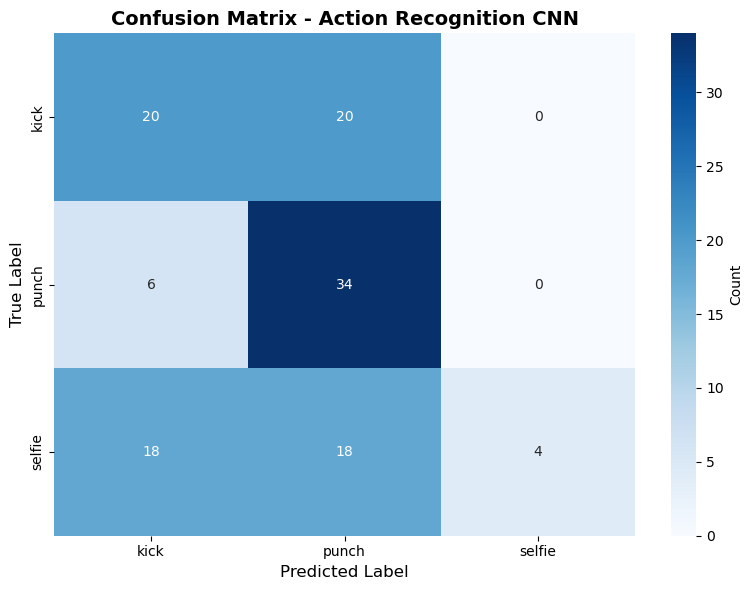

✓ Confusion matrix saved as 'confusion_matrix.png'


In [9]:
print("\n[STEP 7] GENERATE CONFUSION MATRIX")
print("-"*70)

cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, cbar_kws={'label': 'Count'})
plt.title('Confusion Matrix - Action Recognition CNN', fontsize=14, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Confusion matrix saved as 'confusion_matrix.png'")


[STEP 8] PLOT TRAINING HISTORY
----------------------------------------------------------------------


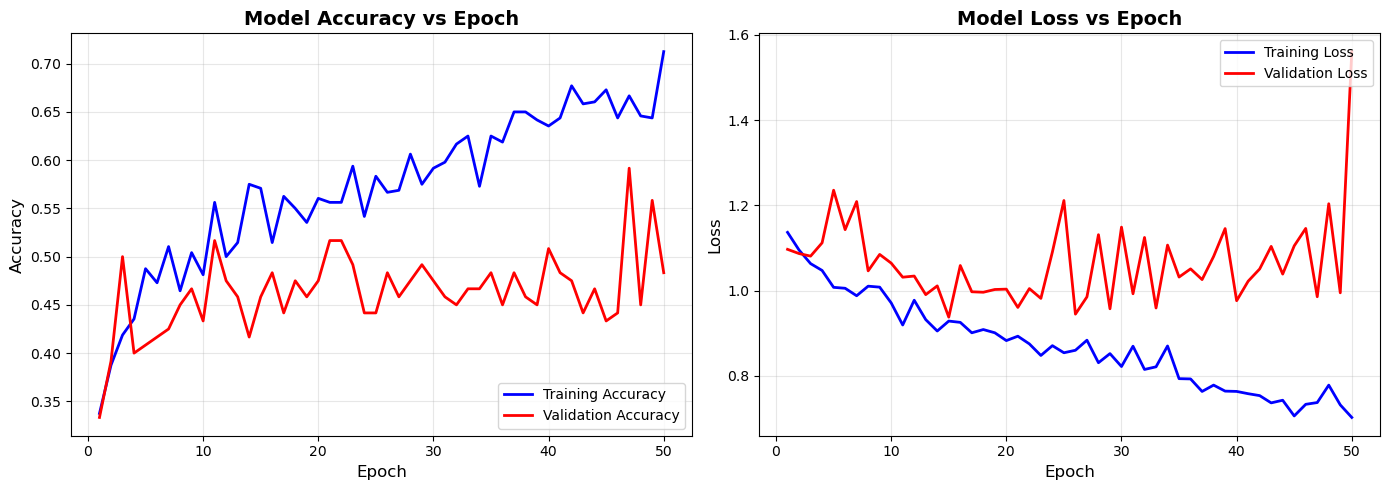

✓ Training plots saved as 'training_history.png'


In [10]:
print("\n[STEP 8] PLOT TRAINING HISTORY")
print("-"*70)

train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
train_loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, train_accuracy, 'b-', linewidth=2, label='Training Accuracy')
axes[0].plot(epochs_range, val_accuracy, 'r-', linewidth=2, label='Validation Accuracy')
axes[0].set_title('Model Accuracy vs Epoch', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=12)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].legend(loc='lower right', fontsize=10)
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, train_loss, 'b-', linewidth=2, label='Training Loss')
axes[1].plot(epochs_range, val_loss, 'r-', linewidth=2, label='Validation Loss')
axes[1].set_title('Model Loss vs Epoch', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=12)
axes[1].set_ylabel('Loss', fontsize=12)
axes[1].legend(loc='upper right', fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_history.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Training plots saved as 'training_history.png'")